In [1]:
# ============================================================
# 1. Imports
# ============================================================

import os

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"

import glob
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

# ============================================================
# 2. Dataset path
# ============================================================

DATA_PATH = "./GEFCom2014-L_V2/Load"


tasks = sorted(
    glob.glob(DATA_PATH + "/Task */L*-train.csv")
)

print("Number of tasks:", len(tasks))

Number of tasks: 15


In [2]:
def parse_gefcom_time(x):

    x = str(x).strip()

    date_part, time_part = x.split()

    hour = int(time_part.split(":")[0])

    year = int(date_part[-4:])

    md = date_part[:-4]


    if len(md) == 2:

        month = int(md[0])
        day = int(md[1])


    elif len(md) == 3:

        month = int(md[0])
        day = int(md[1:])


    elif len(md) == 4:

        month = int(md[:2])
        day = int(md[2:])


    else:

        raise ValueError(
            f"Unknown timestamp format {x}"
        )


    return pd.Timestamp(
        year=year,
        month=month,
        day=day,
        hour=hour
    )

In [3]:
all_data = []


for file in tasks:

    temp = pd.read_csv(file)


    temp["TIMESTAMP"] = (
        temp["TIMESTAMP"]
        .apply(parse_gefcom_time)
    )


    all_data.append(temp)



df = pd.concat(
    all_data,
    ignore_index=True
)



print(df.shape)

(95664, 28)


In [4]:
df = df.drop_duplicates(
    subset=[
        "ZONEID",
        "TIMESTAMP"
    ],
    keep="last"
)


df = df.sort_values(
    [
        "ZONEID",
        "TIMESTAMP"
    ]
)


df.reset_index(
    drop=True,
    inplace=True
)


print(df.shape)

(88752, 28)


In [5]:
df = df[
    df["LOAD"].notna()
]


print(
    "After removing missing load:",
    df.shape
)

After removing missing load: (56280, 28)


In [6]:
weather_cols = [
    f"w{i}"
    for i in range(1,26)
]


df_hourly = (
    df
    .set_index("TIMESTAMP")
    .resample("1h")
    .agg(
        {
            "LOAD":"mean",
            **{
                c:"mean"
                for c in weather_cols
            }
        }
    )
    .reset_index()
)



print(df_hourly.shape)

(60600, 27)


In [7]:
df_hourly = df_hourly.dropna()


df_hourly.reset_index(
    drop=True,
    inplace=True
)


print(
    df_hourly.isna().sum().sum()
)

print(df_hourly.shape)

0
(56280, 27)


In [8]:
df_hourly["hour"] = (
    df_hourly.TIMESTAMP.dt.hour
)


df_hourly["dayofweek"] = (
    df_hourly.TIMESTAMP.dt.dayofweek
)


df_hourly["month"] = (
    df_hourly.TIMESTAMP.dt.month
)

In [9]:
df_hourly["hour_sin"] = np.sin(
    2*np.pi*df_hourly.hour/24
)

df_hourly["hour_cos"] = np.cos(
    2*np.pi*df_hourly.hour/24
)


df_hourly["dow_sin"] = np.sin(
    2*np.pi*df_hourly.dayofweek/7
)

df_hourly["dow_cos"] = np.cos(
    2*np.pi*df_hourly.dayofweek/7
)


df_hourly["month_sin"] = np.sin(
    2*np.pi*df_hourly.month/12
)

df_hourly["month_cos"] = np.cos(
    2*np.pi*df_hourly.month/12
)

In [10]:
demand_features = [
    "LOAD"
]

In [11]:
weather_features = [
    f"w{i}"
    for i in range(1,26)
]

In [12]:
calendar_features = [
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos"
]

In [13]:
n = len(df_hourly)


train_end = int(0.7*n)

val_end = int(0.85*n)



train_df = df_hourly.iloc[:train_end].copy()

val_df = df_hourly.iloc[
    train_end:val_end
].copy()


test_df = df_hourly.iloc[
    val_end:
].copy()



print(
    len(train_df),
    len(val_df),
    len(test_df)
)

39396 8442 8442


In [14]:
load_scaler = StandardScaler()

weather_scaler = StandardScaler()

In [15]:
train_df["LOAD_scaled"] = (
    load_scaler.fit_transform(
        train_df[["LOAD"]]
    )
)


val_df["LOAD_scaled"] = (
    load_scaler.transform(
        val_df[["LOAD"]]
    )
)


test_df["LOAD_scaled"] = (
    load_scaler.transform(
        test_df[["LOAD"]]
    )
)

In [16]:
weather_scaled_train = (
    weather_scaler.fit_transform(
        train_df[weather_features]
    )
)


weather_scaled_val = (
    weather_scaler.transform(
        val_df[weather_features]
    )
)


weather_scaled_test = (
    weather_scaler.transform(
        test_df[weather_features]
    )
)

In [17]:
for i,c in enumerate(weather_features):

    train_df[c+"_scaled"] = (
        weather_scaled_train[:,i]
    )

    val_df[c+"_scaled"] = (
        weather_scaled_val[:,i]
    )

    test_df[c+"_scaled"] = (
        weather_scaled_test[:,i]
    )

In [18]:
train_df.head()

,TIMESTAMP,LOAD,w1,w2,w3,w4,w5,w6,w7,w8,...,w16_scaled,w17_scaled,w18_scaled,w19_scaled,w20_scaled,w21_scaled,w22_scaled,w23_scaled,w24_scaled,w25_scaled
0,2005-01-01 00:00:00,96.7,66.0,66.0,54.0,63.0,70.0,64.0,66.0,68.0,...,0.250808,0.130556,0.358191,-0.204611,0.444023,0.027578,0.113393,0.250361,0.305919,0.058472
1,2005-01-01 01:00:00,87.0,66.0,64.0,53.0,62.0,70.0,64.0,67.0,68.0,...,0.046931,0.069362,0.358191,-0.204611,0.377374,0.091874,-0.011750,0.250361,0.244632,0.058472
2,2005-01-01 02:00:00,80.8,66.0,63.0,55.0,62.0,68.0,64.0,67.0,66.0,...,-0.021028,0.069362,0.430096,-0.204611,0.310726,0.091874,-0.011750,0.250361,0.244632,0.058472
3,2005-01-01 03:00:00,78.2,64.0,63.0,56.0,62.0,68.0,64.0,67.0,66.0,...,-0.021028,-0.053025,0.430096,-0.204611,0.244078,0.027578,-0.011750,0.128865,0.183346,0.119649
4,2005-01-01 04:00:00,76.6,64.0,63.0,56.0,62.0,68.0,64.0,66.0,64.0,...,-0.021028,-0.053025,0.430096,-0.204611,0.177429,-0.036718,-0.011750,0.128865,0.183346,0.119649


In [19]:
import torch
from torch.utils.data import Dataset, DataLoader


class EnergyDataset(Dataset):

    def __init__(
        self,
        df,
        history=168,
        horizon=24
    ):

        self.history = history
        self.horizon = horizon


        # Demand
        self.demand = (
            df["LOAD_scaled"]
            .values
            .astype(np.float32)
        )


        # Weather
        weather_cols = [
            f"w{i}_scaled"
            for i in range(1,26)
        ]

        self.weather = (
            df[weather_cols]
            .values
            .astype(np.float32)
        )


        # Calendar
        calendar_cols = [
            "hour_sin",
            "hour_cos",
            "dow_sin",
            "dow_cos",
            "month_sin",
            "month_cos"
        ]

        self.calendar = (
            df[calendar_cols]
            .values
            .astype(np.float32)
        )


    def __len__(self):

        return (
            len(self.demand)
            -
            self.history
            -
            self.horizon
        )


    def __getitem__(self, idx):

        start = idx
        end = idx + self.history


        target_start = end
        target_end = end + self.horizon


        demand = self.demand[start:end]

        weather = self.weather[start:end]

        calendar = self.calendar[start:end]


        # previous day same hours
        last_day = self.demand[
            end-24:end
        ]


        # true future load
        future = self.demand[
            target_start:target_end
        ]


        return {

            "demand":
                torch.tensor(demand)
                .unsqueeze(-1),


            "weather":
                torch.tensor(weather),


            "calendar":
                torch.tensor(calendar),


            "last_day":
                torch.tensor(last_day),


            "target":
                torch.tensor(future)

        }

In [20]:
train_dataset = EnergyDataset(
    train_df,
    history=168,
    horizon=24
)


val_dataset = EnergyDataset(
    val_df,
    history=168,
    horizon=24
)


test_dataset = EnergyDataset(
    test_df,
    history=168,
    horizon=24
)

In [21]:
BATCH_SIZE = 64


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [22]:
class DomainEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        d_model=32
    ):
        super().__init__()


        self.projection = nn.Linear(
            input_dim,
            d_model
        )


        self.norm = nn.LayerNorm(
            d_model
        )


    def forward(self,x):

        # x:
        # batch, time, features

        x = self.projection(x)

        x = self.norm(x)

        return x

In [23]:
class PositionalEncoding(nn.Module):

    def __init__(
        self,
        d_model,
        max_len=500
    ):

        super().__init__()


        pe = torch.zeros(
            max_len,
            d_model
        )


        position = torch.arange(
            0,
            max_len
        ).unsqueeze(1)


        div_term = torch.exp(
            torch.arange(
                0,
                d_model,
                2
            )
            *
            (-np.log(10000.0)/d_model)
        )


        pe[:,0::2] = torch.sin(
            position*div_term
        )


        pe[:,1::2] = torch.cos(
            position*div_term
        )


        self.register_buffer(
            "pe",
            pe.unsqueeze(0)
        )


    def forward(self,x):

        return x + self.pe[:,:x.size(1)]

In [24]:
class DomainFusion(nn.Module):

    def __init__(
        self,
        d_model=64,
        heads=4
    ):

        super().__init__()


        self.d_model = d_model


        # Learn domain importance weights
        self.domain_gate = nn.Sequential(

            nn.Linear(
                d_model * 3,
                d_model
            ),

            nn.ReLU(),

            nn.Linear(
                d_model,
                3
            )
        )


        # Temporal attention after domain fusion
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=heads,
            batch_first=True
        )


        self.norm = nn.LayerNorm(
            d_model
        )


        self.dropout = nn.Dropout(
            0.1
        )


    def forward(
        self,
        demand,
        weather,
        calendar
    ):


        # Each:
        # (batch,168,64)


        domain_stack = torch.stack(
            [
                demand,
                weather,
                calendar
            ],
            dim=2
        )


        # shape:
        # (batch,168,3,64)



        # Create domain descriptor

        domain_concat = torch.cat(
            [
                demand,
                weather,
                calendar
            ],
            dim=-1
        )


        # (batch,168,192)


        gate_logits = self.domain_gate(
            domain_concat
        )


        # (batch,168,3)


        domain_weights = torch.softmax(
            gate_logits,
            dim=-1
        )


        # (batch,168,3,1)

        domain_weights = domain_weights.unsqueeze(-1)



        # Weighted domain fusion

        x = (
            domain_stack
            *
            domain_weights
        ).sum(
            dim=2
        )


        # x:
        # (batch,168,64)



        # Temporal self-attention

        attn_out,_ = self.attention(
            x,
            x,
            x
        )


        x = self.norm(
            x + self.dropout(attn_out)
        )


        return x

In [25]:
class DreamFormer(nn.Module):

    def __init__(
        self,
        d_model=64,
        horizon=24
    ):

        super().__init__()


        self.demand_encoder = DomainEncoder(
            1,
            d_model
        )


        self.weather_encoder = DomainEncoder(
            25,
            d_model
        )


        self.calendar_encoder = DomainEncoder(
            6,
            d_model
        )


        self.position = PositionalEncoding(
            d_model
        )


        self.fusion = DomainFusion(
            d_model
        )


        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            batch_first=True
        )


        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )


        self.head = nn.Sequential(

            nn.Linear(
                d_model,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                horizon
            )
        )


    def forward(
        self,
        demand,
        weather,
        calendar,
        last_day
    ):


        d = self.demand_encoder(
            demand
        )

        w = self.weather_encoder(
            weather
        )

        c = self.calendar_encoder(
            calendar
        )


        d = self.position(d)
        w = self.position(w)
        c = self.position(c)



        x = self.fusion(
            d,
            w,
            c
        )


        x = self.transformer(
            x
        )

        x = x[:,-1,:]

        residual = self.head(x)
        forecast = residual + last_day

        return forecast

In [26]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(device)


model = DreamFormer().to(device)


batch = next(iter(train_loader))


pred = model(
    batch["demand"].to(device),
    batch["weather"].to(device),
    batch["calendar"].to(device),
    batch["last_day"].to(device)
)


print(pred.shape)

mps
torch.Size([64, 24])


In [27]:
import torch.optim as optim

criterion = nn.HuberLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

In [28]:
import time
from tqdm.auto import tqdm

/opt/anaconda3/envs/AI/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [29]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device,
    epoch
):

    model.train()

    total_loss = 0.0


    progress_bar = tqdm(
        loader,
        desc=f"Epoch {epoch} | Training",
        leave=False
    )


    for batch_idx, batch in enumerate(progress_bar):

        demand = batch["demand"].to(device)
        weather = batch["weather"].to(device)
        calendar = batch["calendar"].to(device)

        last_day = batch["last_day"].to(device)

        target = batch["target"].to(device)


        optimizer.zero_grad()


        prediction = model(
            demand,
            weather,
            calendar,
            last_day
        )


        loss = criterion(
            prediction,
            target
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )


        optimizer.step()


        total_loss += loss.item()


        avg_loss = total_loss / (batch_idx + 1)


        progress_bar.set_postfix(
            {
                "loss": f"{avg_loss:.5f}",
                "lr": optimizer.param_groups[0]["lr"]
            }
        )


    return total_loss / len(loader)

In [30]:
def evaluate(
    model,
    loader,
    criterion,
    device,
    epoch
):

    model.eval()

    total_loss = 0.0


    progress_bar = tqdm(
        loader,
        desc=f"Epoch {epoch} | Validation",
        leave=False
    )


    with torch.no_grad():

        for batch_idx, batch in enumerate(progress_bar):

            demand = batch["demand"].to(device,non_blocking=True)

            weather = batch["weather"].to(device,non_blocking=True)

            calendar = batch["calendar"].to(device,non_blocking=True)

            last_day = batch["last_day"].to(device,non_blocking=True)

            target = batch["target"].to(device,non_blocking=True)


            prediction = model(
                demand,
                weather,
                calendar,
                last_day
            )


            loss = criterion(
                prediction,
                target
            )


            total_loss += loss.item()


            avg_loss = (
                total_loss /
                (batch_idx+1)
            )


            progress_bar.set_postfix(
                {
                    "loss": f"{avg_loss:.5f}"
                }
            )


    return total_loss / len(loader)

In [31]:
EPOCHS = 20


best_val_loss = float("inf")


history = {
    "train_loss":[],
    "val_loss":[],
    "lr":[]
}


checkpoint_path = "dreamformer_v1_best.pt"



for epoch in range(1, EPOCHS+1):


    start_time = time.time()


    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device,
        epoch
    )


    val_loss = evaluate(
        model,
        val_loader,
        criterion,
        device,
        epoch
    )


    epoch_time = (
        time.time()-start_time
    )


    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )


    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["lr"].append(
        current_lr
    )


    print("\n" + "="*70)

    print(
        f"Epoch [{epoch}/{EPOCHS}]"
    )

    print(
        f"Train Loss : {train_loss:.6f}"
    )

    print(
        f"Val Loss   : {val_loss:.6f}"
    )

    print(
        f"Learning Rate : {current_lr:.8f}"
    )

    print(
        f"Time : {epoch_time:.2f} sec"
    )


    # Save best model

    if val_loss < best_val_loss:


        best_val_loss = val_loss


        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "val_loss":
                    val_loss,
                "train_loss":
                    train_loss
            },
            checkpoint_path
        )


        print(
            f"✓ Best model saved "
            f"(Val Loss: {val_loss:.6f})"
        )


    else:

        print(
            f"No improvement "
            f"(Best: {best_val_loss:.6f})"
        )


    print("="*70)


Epoch [1/20]
Train Loss : 0.101493
Val Loss   : 0.090869
Learning Rate : 0.00010000
Time : 100.22 sec
✓ Best model saved (Val Loss: 0.090869)



Epoch [2/20]
Train Loss : 0.071762
Val Loss   : 0.086762
Learning Rate : 0.00010000
Time : 127.03 sec
✓ Best model saved (Val Loss: 0.086762)



Epoch [3/20]
Train Loss : 0.063509
Val Loss   : 0.084293
Learning Rate : 0.00010000
Time : 110.20 sec
✓ Best model saved (Val Loss: 0.084293)



Epoch [4/20]
Train Loss : 0.058138
Val Loss   : 0.075821
Learning Rate : 0.00010000
Time : 103.95 sec
✓ Best model saved (Val Loss: 0.075821)



Epoch [5/20]
Train Loss : 0.054225
Val Loss   : 0.078634
Learning Rate : 0.00010000
Time : 100.80 sec
No improvement (Best: 0.075821)



Epoch [6/20]
Train Loss : 0.050665
Val Loss   : 0.081767
Learning Rate : 0.00010000
Time : 146.93 sec
No improvement (Best: 0.075821)


... (5 outputs left out)


Epoch [12/20]
Train Loss : 0.036888
Val Loss   : 0.085521
Learning Rate : 0.00010000
Time : 112.48 sec
No improvement (Best: 0.071425)



Epoch [13/20]
Train Loss : 0.035396
Val Loss   : 0.083827
Learning Rate : 0.00010000
Time : 149.42 sec
No improvement (Best: 0.071425)



Epoch [14/20]
Train Loss : 0.033208
Val Loss   : 0.086782
Learning Rate : 0.00010000
Time : 141.15 sec
No improvement (Best: 0.071425)


KeyboardInterrupt: 

In [32]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [33]:
def predict(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    actuals = []


    with torch.no_grad():

        for batch in loader:

            demand = batch["demand"].to(device)

            weather = batch["weather"].to(device)

            calendar = batch["calendar"].to(device)

            last_day = batch["last_day"].to(device)


            target = batch["target"]


            output = model(
                demand,
                weather,
                calendar,
                last_day
            )


            predictions.append(
                output.cpu().numpy()
            )


            actuals.append(
                target.numpy()
            )


    predictions = np.concatenate(
        predictions,
        axis=0
    )


    actuals = np.concatenate(
        actuals,
        axis=0
    )


    return predictions, actuals

In [34]:
pred_scaled, y_scaled = predict(
    model,
    test_loader,
    device
)


print(pred_scaled.shape)
print(y_scaled.shape)

(8250, 24)
(8250, 24)


In [35]:
pred = load_scaler.inverse_transform(
    pred_scaled.reshape(-1,1)
)


y_true = load_scaler.inverse_transform(
    y_scaled.reshape(-1,1)
)

In [36]:
pred = pred.reshape(
    pred_scaled.shape
)


y_true = y_true.reshape(
    y_scaled.shape
)


print(pred.shape)

(8250, 24)


In [37]:
mae = mean_absolute_error(
    y_true.flatten(),
    pred.flatten()
)

rmse = np.sqrt(
    mean_squared_error(
        y_true.flatten(),
        pred.flatten()
    )
)

mape = np.mean(
    np.abs(
        (y_true-pred)
        /
        y_true
    )
) * 100

print("="*50)

print(
    f"MAE  : {mae:.4f}"
)

print(
    f"RMSE : {rmse:.4f}"
)

print(
    f"MAPE : {mape:.4f}%"
)

print("="*50)


MAE  : 12.7778
RMSE : 19.1182
MAPE : 9.6463%


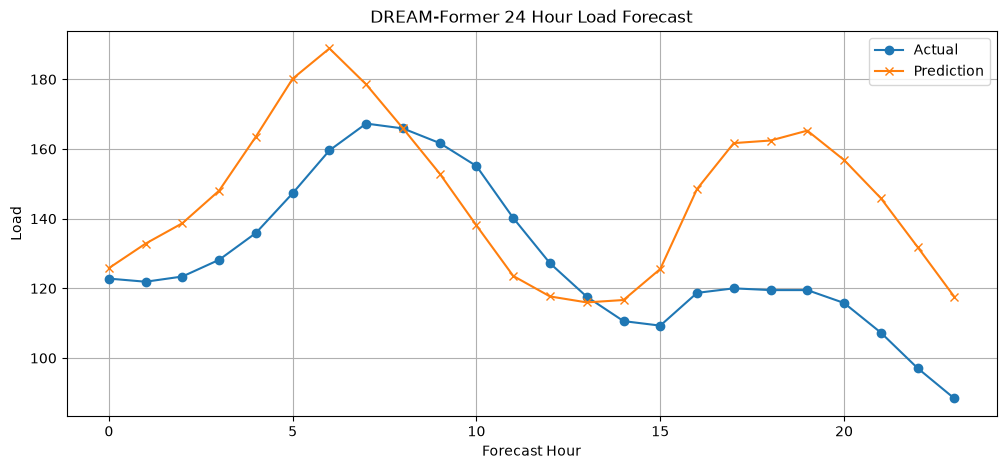

In [38]:
sample_id = 20


plt.figure(
    figsize=(12,5)
)


plt.plot(
    y_true[sample_id],
    marker="o",
    label="Actual"
)


plt.plot(
    pred[sample_id],
    marker="x",
    label="Prediction"
)


plt.xlabel(
    "Forecast Hour"
)

plt.ylabel(
    "Load"
)


plt.title(
    "DREAM-Former 24 Hour Load Forecast"
)


plt.legend()

plt.grid()

plt.show()

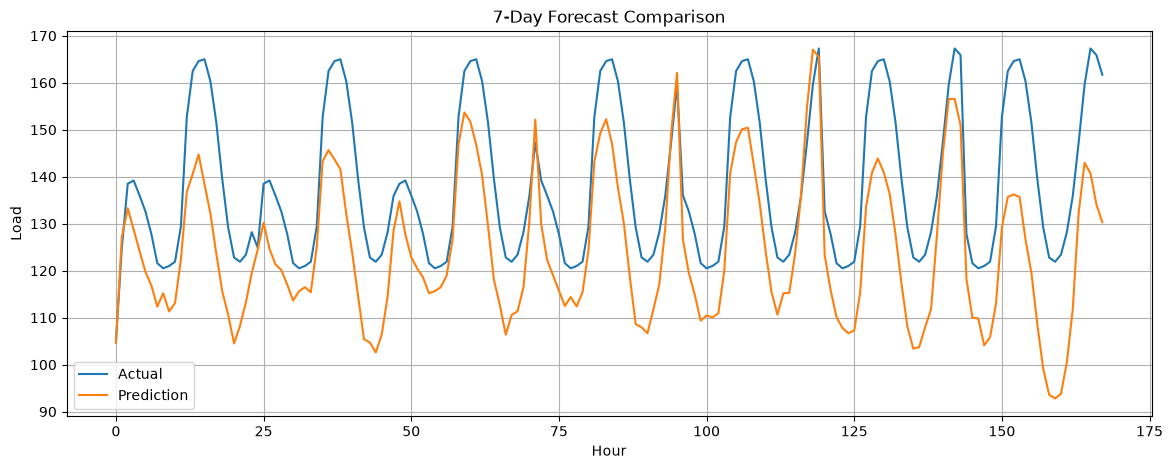

In [39]:
days = 7

plt.figure(
    figsize=(14,5)
)


plt.plot(
    y_true[:days].flatten(),
    label="Actual"
)


plt.plot(
    pred[:days].flatten(),
    label="Prediction"
)


plt.xlabel(
    "Hour"
)


plt.ylabel(
    "Load"
)


plt.title(
    "7-Day Forecast Comparison"
)


plt.legend()

plt.grid()

plt.show()